<a href="https://colab.research.google.com/github/viniuniv/PDI-m2.1/blob/main/PDI/Pr%C3%A1tica_Processamento_Morfol%C3%B3gico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Sinais: Imagens

# Exercício Avalitivo de Processamento Morfológico

### Tutoriais da OpenCV

- https://docs.opencv.org/master/d9/df8/tutorial_root.html
- https://www.geeksforgeeks.org/opencv-python-tutorial/

## Processamento Morfológico
#### Obs: Utilize imagens em preto e branco.


### Erosão e Dilatação

1. Implemente a sua própria versão da erosão em formato de função, com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma) e aplique o algoritmos na na figura ImagensMorfologia/Fig0905(a)(wirebond-mask)
2. Implemente a sua própria versão da dilatação em formato de função, com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma) e aplique o algoritmos na na figura ImagensMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels)
4. Relate as observações visíveis nas imagens de saída com os processamentos aplicados, descrevendo o comportamento visual em relação as bordas, junção, perda de informação e mlhoria na qualidade visual.
5. Aplique o seu algoritmo de detecção de borda (roberts ou sobel) a imagem ImagensMorfologia/Fig0905(a)(wirebond-mask) antes e depois de utilizar a dilatação/erosão e relate os resultados.

#### Dicas
 - Você pode adicionar ruído nas imagens usando a função random_noise: `from skimage.util import random_noise`. Cuidado com o retorno da função, talvez seja necessário regularizar a mesma novamente para o intervalo de 0 à 255. O ruído pode ser intensificado ou excluído com processamento morfológico.

In [32]:
## importação de dependências e declaração dos kernels
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
from numpy.typing import NDArray

kernel_3x3_1 = [
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
]
kernel_3x3_2 = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
]
kernel_4x4_1 = [
    [0, 1, 1, 0],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [0, 1, 1, 0],
]
kernel_4x4_2 = [
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
]
kernel_5x5_1 = [
  [0, 0, 1, 0, 0],
  [0, 1, 1, 1, 0],
  [1, 1, 1, 1, 1],
  [0, 1, 1, 1, 0],
  [0, 0, 1, 0, 0]
]
kernel_5x5_2 = [
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
]


In [73]:
## funções de corrosão e dilatação
def erosao(img, kernel = kernel_3x3_1):
  kernel = np.array(kernel)
  h, w = img.shape[:2]
  kh = len(kernel)
  kw = len(kernel[0])

  ry = kh // 2
  rx = kw // 2

  out = np.zeros_like(img)

  for y in range(h):
    for x in range(w):
      if _hit_corrosao(img, y, x, kernel, kh, kw, ry, rx, h, w):
        out[y, x] = 255
  return out

def _hit_erosao(img, y, x, kernel, kh, kw, ry, rx, h, w):
  ## retorna se o kernel corresponde completamente a pixels brancos
  for ky in range(kh):
    for kx in range(kw):
      if kernel[ky, kx] == 0:
        continue
      iy = y + ky - ry
      ix = x + kx - rx
      if iy < 0 or iy >= h or ix < 0 or ix >= w:
        return False
      if img[iy, ix] == 0:
        return False
  return True


def dilatacao(img, kernel = kernel_3x3_1):
  kernel = np.array(kernel)

  h, w = img.shape[:2]
  kh = len(kernel)
  kw = len(kernel[0])

  ry = kh // 2
  rx = kw // 2
  out = np.zeros_like(img)
  for y in range(h):
    for x in range(w):
      if _hit_dilatacao(img, y, x, kernel, kh, kw, ry, rx, h, w):
        out[y, x] = 255

  return out

def _hit_dilatacao(img, y, x, kernel, kh, kw, ry, rx, h, w):
  ## retorna se pelo menos um dos pixels dentro do espaço do kernel é branco
  for ky in range(kh):
    for kx in range(kw):
      if kernel[ky, kx] == 0:
        continue
      iy = y + ky - ry
      ix = x + kx - rx
      if iy < 0 or iy >= h or ix < 0 or ix >= w:
        return False
      if img[iy, ix] != 0:
        return True
  return False





Algoritmo de Erosão:
Kernels utilizados: 3x3_1, 4x4_2, 5x5_1


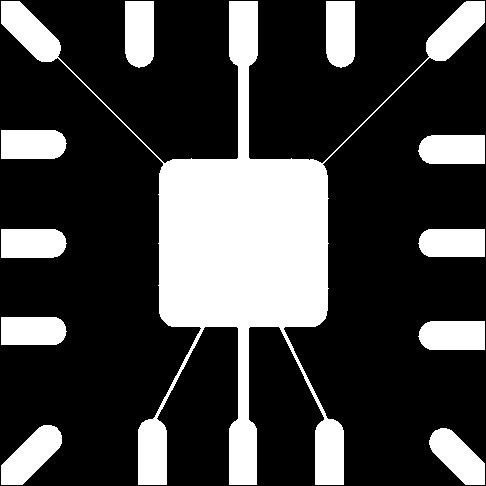

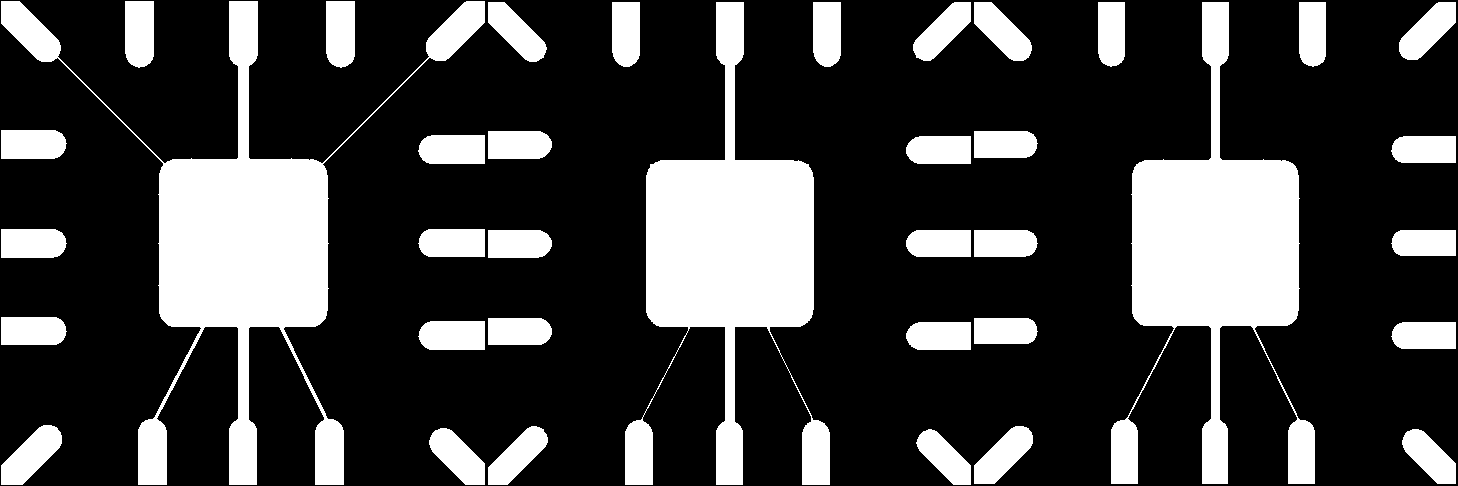

OBSERVAÇÃO:
Nota-se, pelos resultados da aplicação de diferentes kernels, 
que o formato do kernel utilizado tem grande impacto na imagem de saída, 
afetando o ângulo e espessura de linhas e bordas que são removidas, 
resultado em diferentes deformações.

Dependendo do objetivo do tratamento da imagem, um kernel diferente deverá ser utilizado, 
por exeplo, um kernel mais espesso e sólido é melhor para a tarefa de remover todos os traços, 
enquanto um mais fino e com os cantos negativos pode ser melhor para remover as linhas em um determinado ângulo.


In [74]:
print("Algoritmo de Erosão:")
print("Kernels utilizados: 3x3_1, 4x4_2, 5x5_1")

imge = cv2.imread("/content/Fig0905(a)(wirebond-mask).tif", cv2.IMREAD_GRAYSCALE)

imge1 = erosao(imge)
imge2 = erosao(imge, kernel_4x4_2)
imge3 = erosao(imge, kernel_5x5_1)

cv2_imshow(imge1)
cv2_imshow(np.hstack([imge1, imge2, imge3]))
print("OBSERVAÇÃO:\nNota-se, pelos resultados da aplicação de diferentes kernels, \nque o formato do kernel utilizado tem grande impacto na imagem de saída, \nafetando o ângulo e espessura de linhas e bordas que são removidas, \nresultado em diferentes deformações.")
print("\nDependendo do objetivo do tratamento da imagem, um kernel diferente deverá ser utilizado, \npor exeplo, um kernel mais espesso e sólido é melhor para a tarefa de remover todos os traços, \nenquanto um mais fino e com os cantos negativos pode ser melhor para remover as linhas em um determinado ângulo.")

Algoritmos de Dilatação:
Kernels utilizados: 3x3_1, 4x4_2, 5x5_2


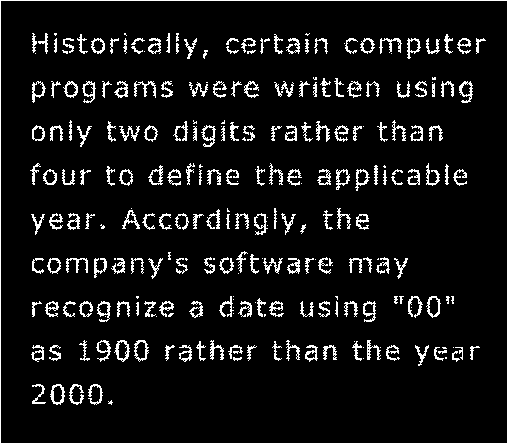

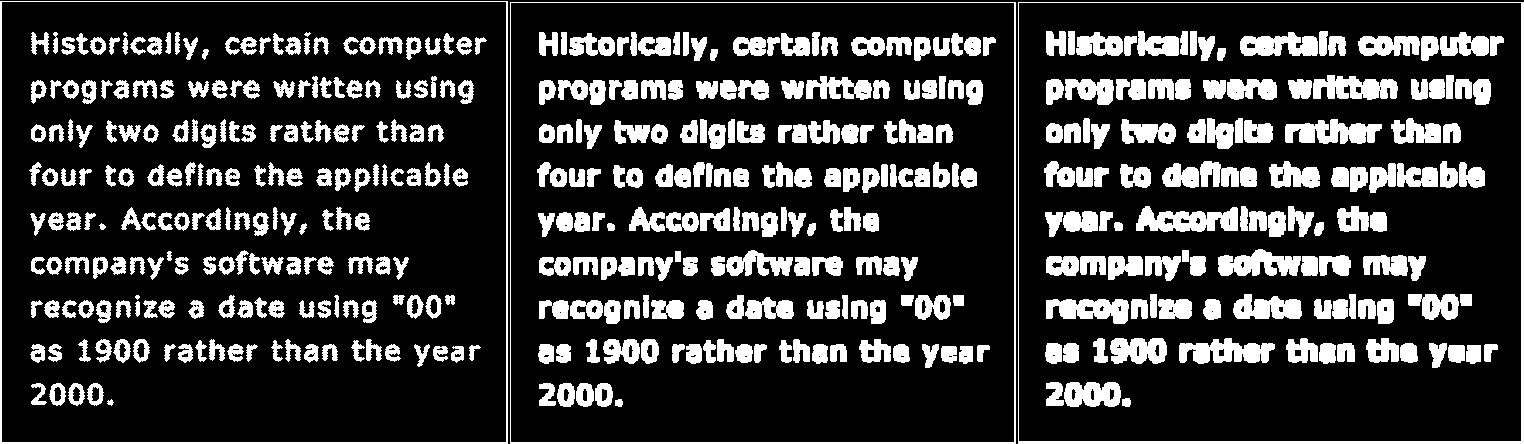

OBSERVAÇÃO:
O algoritmo de dilatação, aplicado sozinho, tem um efeito marginalmente positivo na legibilidade do texto.
Enquanto boa parte da poluição interna foi removida, a expansão também acentuou os pixels que estavam fora da forma ideal das letras.
A aplicação de kernels de tamanhos maiores resultou apenas no engrossamento da fonte em relação aos kernels menores.


In [71]:
print("Algoritmos de Dilatação:")
print("Kernels utilizados: 3x3_1, 4x4_2, 5x5_2")
imgd = cv2.imread("/content/Fig0907(a)(text_gaps_1_and_2_pixels).tif", cv2.IMREAD_GRAYSCALE)

imgd1 = dilatacao(imgd)
imgd2 = dilatacao(imgd, kernel_4x4_2)
imgd3 = dilatacao(imgd, kernel_5x5_2)

cv2_imshow(imgd)
cv2_imshow(np.hstack([imgd1, imgd2, imgd2]))
print("OBSERVAÇÃO:")
print("O algoritmo de dilatação, aplicado sozinho, tem um efeito marginalmente positivo na legibilidade do texto.")
print("Enquanto boa parte da poluição interna foi removida, a expansão também acentuou os pixels que estavam fora da forma ideal das letras.")
print("A aplicação de kernels de tamanhos maiores resultou apenas no engrossamento da fonte em relação aos kernels menores.")

Comparação Detecção de bordas:


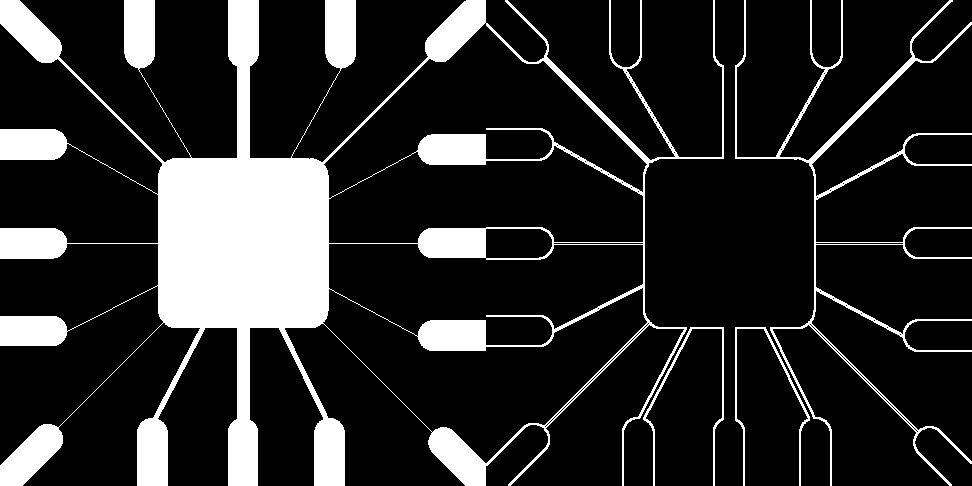

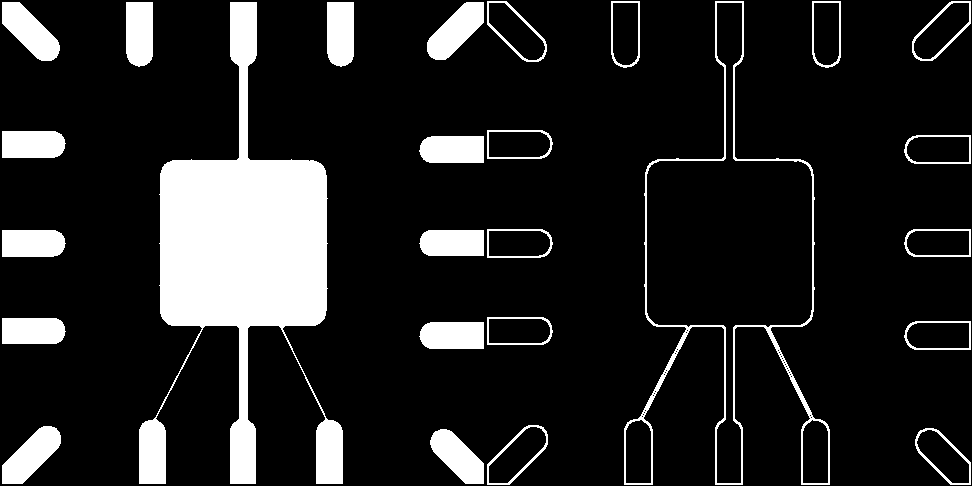

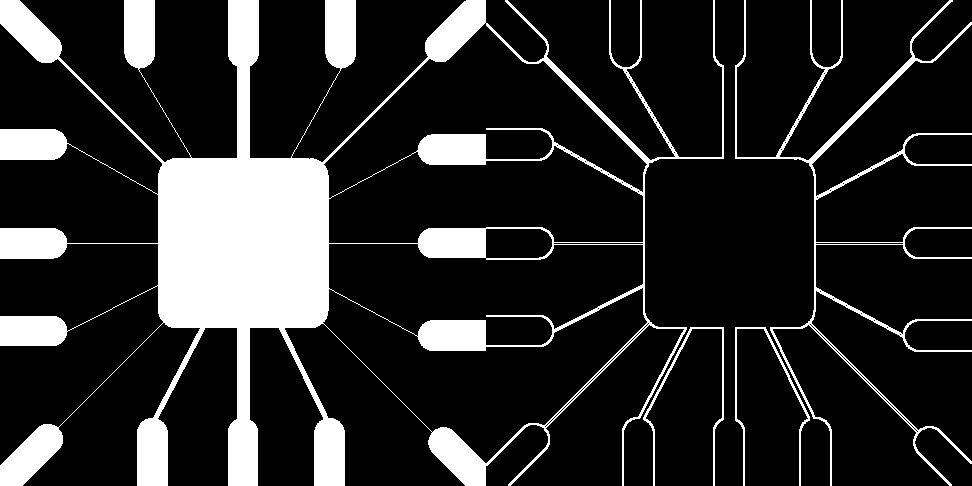

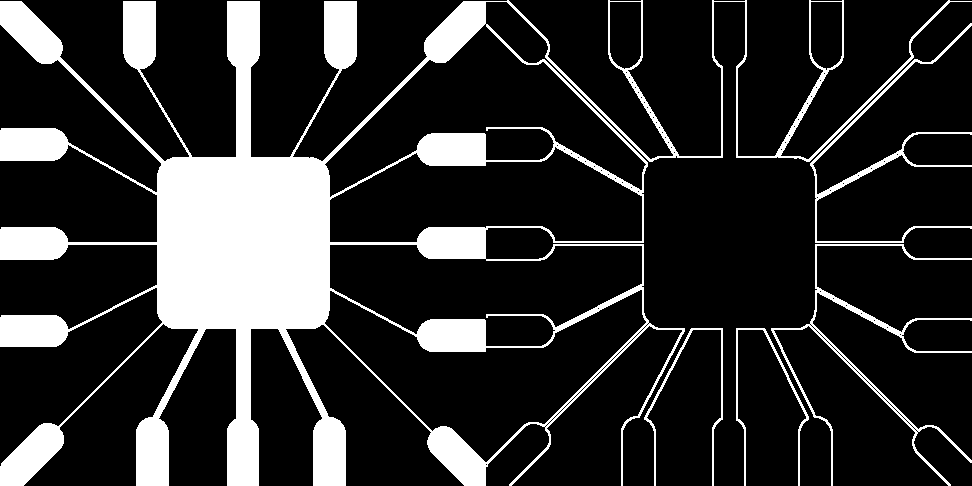

OBSERVAÇÃO:
Ao aplicar o algoritmo sobel às imagens, nota-se que, 
enquanto a erosão reduz as bordas ou as remove completamente, 
a dilatação as aumenta e acentua.


In [84]:
print("Comparação Detecção de bordas:")

def magnitude_sobel(img):
  gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
  gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
  return cv2.convertScaleAbs(cv2.magnitude(gx, gy))


magnitude = cv2.magnitude(gx, gy)
magnitude = cv2.convertScaleAbs(magnitude)
cv2_imshow(np.hstack([imge, magnitude_sobel(imge)]))
cv2_imshow(np.hstack([imge3, magnitude_sobel(imge3)]))

imgd_m = imge
imgd_m1 = dilatacao(imgd_m)

cv2_imshow(np.hstack([imgd_m, magnitude_sobel(imgd_m)]))
cv2_imshow(np.hstack([imgd_m1, magnitude_sobel(imgd_m1)]))

print("OBSERVAÇÃO:")
print("Ao aplicar o algoritmo sobel às imagens, nota-se que, \nenquanto a erosão reduz as bordas ou as remove completamente, \na dilatação as aumenta e acentua.")


### Abertura e Fechamento

5. Implemente a sua versão do algoritmo de abertura em forma de função com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma)
6. Implemente a sua versão do algoritmo de fechamento em forma de função com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma)
7. Aplique o processamento indicado na image abaixo usando a figura ImagensMorfologia/Fig0911(a)(noisy_fingerprint)

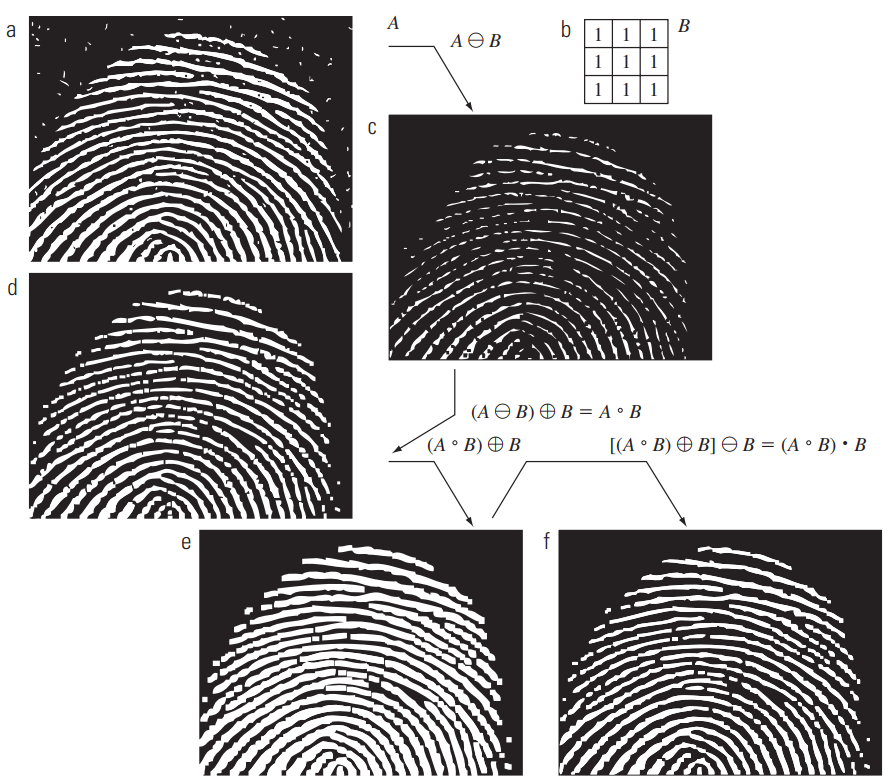

A


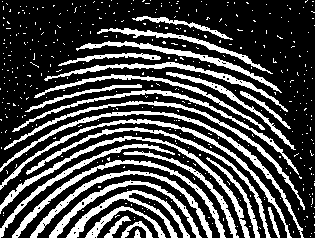

C


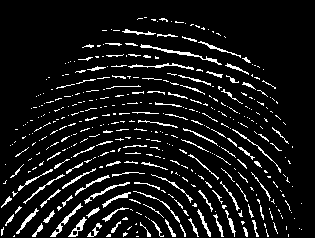

D


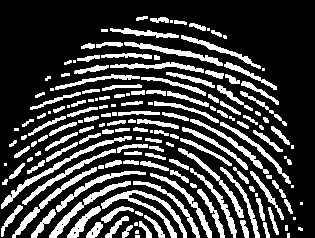

E


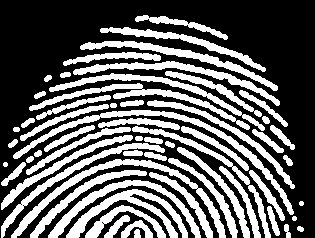

F


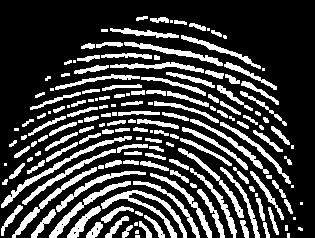

In [97]:
## funções de abertura e fechamento, utilizando as funções de dilatação e erosão já feitas
def abertura(img, kernel, qtd = 1):
  for _i in range(qtd):
    img = erosao(img, kernel)
    img = dilatacao(img, kernel)
  return img

def fechamento(img, kernel, qtd=1):
  for _i in range(qtf):
    img = dilatacao(img, kernel)
    img = erosao(img, kernel)
  return img



imgaf_a = cv2.imread("/content/Fig0911(a)(noisy_fingerprint).tif", cv2.IMREAD_GRAYSCALE)
imgaf_c = erosao(imgaf, kernel_3x3_2) ## kernel 3x3_2 = kernel B da ilustração
imgaf_d = abertura(imgaf, kernel_3x3_2)
imgaf_e = dilatacao(abertura(imgaf, kernel_3x3_2))
imgaf_f = abertura(imgaf, kernel_3x3_2, 2)

print("A")
cv2_imshow(imgaf_a)
print("C")
cv2_imshow(imgaf_c)
print("D")
cv2_imshow(imgaf_d)
print("E")
cv2_imshow(imgaf_e)
print("F")
cv2_imshow(imgaf_f)
